<a href="https://colab.research.google.com/github/arijkhemiri2002/DriveSight/blob/kenza/comparaison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!git clone https://github.com/arijkhemiri2002/DriveSight.git
%cd DriveSight
!git checkout -b experiment/yolo-model-comparison

Cloning into 'DriveSight'...
remote: Enumerating objects: 7542, done.
remote: Counting objects: 100% (22/22), done.
remote: Compressing objects: 100% (16/16), done.
remote: Total 7542 (delta 5), reused 18 (delta 4), pack-reused 7520 (from 2)
Receiving objects: 100% (7542/7542), 315.90 MiB | 24.25 MiB/s, done.
Resolving deltas: 100% (4938/4938), done.
Updating files: 100% (7509/7509), done.
/content/DriveSight
Switched to a new branch 'experiment/yolo-model-comparison'


In [ ]:
%cd /content/DriveSight

!git branch --show-current
!ls
!ls src/detection

/content/DriveSight
experiment/yolo-model-comparison
data  notebooks  README.md  requirements.txt  src
train_yolo.ipynb


In [ ]:
import os

for path in [
    "/content/DriveSight/data/dataset",
    "/content/yolo",
    "/content/yolo/data.yaml",
    "/content/yolo.zip"
]:
    print(f"{path} -> {'Existe' if os.path.exists(path) else 'Absent'}")

/content/DriveSight/data/dataset -> Existe
/content/yolo -> Absent
/content/yolo/data.yaml -> Absent
/content/yolo.zip -> Absent


In [ ]:
import os

for root, dirs, files in os.walk("/content/DriveSight/data/dataset"):
    level = root.replace("/content/DriveSight/data/dataset", "").count(os.sep)
    if level > 2:
        dirs[:] = []
        continue

    print("  " * level + os.path.basename(root) + "/")

    for file in files[:10]:
        print("  " * (level + 1) + file)

    if level == 2:
        dirs[:] = []

dataset/
  labels_json/
    train/
      31a9e4c6-0c51364b.json
      60e2fc8e-803218f4.json
      0837760b-d0fc2090.json
      64b92603-a89eeac5.json
      37ccc21b-896d09d2.json
      3e1a7d8e-d9194441.json
      05faab83-7761d124.json
      2410ad60-59a0e430.json
      73b82484-c74bab91.json
      0ac3cbf4-73c76d25.json
  info/
    train/
      31a9e4c6-0c51364b.json
      60e2fc8e-803218f4.json
      0837760b-d0fc2090.json
      64b92603-a89eeac5.json
      37ccc21b-896d09d2.json
      3e1a7d8e-d9194441.json
      05faab83-7761d124.json
      2410ad60-59a0e430.json
      73b82484-c74bab91.json
      0ac3cbf4-73c76d25.json
  images/
    train/
      1f45df68-26795801.jpg
      4263d0a4-934b86c2.jpg
      772ffd30-b9bea776.jpg
      692c3ce6-d7484ddb.jpg
      9385ad9b-11d94c45.jpg
      2e44968d-15c430d5.jpg
      684715d5-23039d9c.jpg
      23112889-a8ce8bc7.jpg
      11dc1774-6eb9c063.jpg
      451d541a-68edeb3e.jpg


In [ ]:
import os

base = "/content/DriveSight/data/dataset"

for folder in ["images", "labels_json", "info"]:
    path = os.path.join(base, folder)
    print(f"\n{folder}:")
    if os.path.exists(path):
        print("Sous-dossiers :", os.listdir(path))
        for split in os.listdir(path):
            split_path = os.path.join(path, split)
            if os.path.isdir(split_path):
                print(f"  {split}: {len(os.listdir(split_path))} fichiers")
    else:
        print("Dossier absent")


images:
Sous-dossiers : ['train']
  train: 2500 fichiers

labels_json:
Sous-dossiers : ['train']
  train: 2500 fichiers

info:
Sous-dossiers : ['train']
  train: 2500 fichiers


In [ ]:
import os

base = "/content/DriveSight"

for root, dirs, files in os.walk(base):
    dirs[:] = [d for d in dirs if d != ".git"]

    for file in files:
        if file in ["preprocessing.py", "data.yaml", "verification.py"]:
            print(os.path.join(root, file))

/content/DriveSight/src/features/preprocessing.py
/content/DriveSight/src/features/verification.py


In [ ]:
%cd /content/DriveSight

with open("src/features/preprocessing.py", "r", encoding="utf-8") as f:
    print(f.read())

/content/DriveSight
import json, glob, os, random, shutil
from collections import Counter, defaultdict

# ---------- À ADAPTER ----------
BASE   = r"C:\Users\arijk\Desktop\DriveSight\DriveSight\data\dataset"
IMG_IN = os.path.join(BASE, "images", "train")
LAB_IN = os.path.join(BASE, "labels_json", "train")
OUT    = r"C:\Users\arijk\Desktop\DriveSight\DriveSight\data\yolo"
RATIOS = {"train": 0.70, "val": 0.15, "test": 0.15}
MOVE   = False        # False = copie (garde dataset intact) ; True = déplace (économise de la place)
SEED   = 42
W, H   = 1280, 720
# --------------------------------

# 9 classes : "train" retirée. Noms BDD100K -> indice YOLO
CLASSES = ["pedestrian", "rider", "car", "truck", "bus",
           "motorcycle", "bicycle", "traffic light", "traffic sign"]
BDD2ID = {"person": 0, "rider": 1, "car": 2, "truck": 3, "bus": 4,
          "motor": 5, "bike": 6, "traffic light": 7, "traffic sign": 8}
RARE_TAGS = {"night", "snowy", "rainy", "foggy"}   # contextes à répartir aussi e

In [ ]:
%cd /content/DriveSight

from pathlib import Path

source = Path("src/features/preprocessing.py")
destination = Path("src/features/preprocessing_colab.py")

code = source.read_text(encoding="utf-8")

code = code.replace(
    r'C:\Users\arijk\Desktop\DriveSight\DriveSight\data\dataset',
    '/content/DriveSight/data/dataset'
)

code = code.replace(
    r'C:\Users\arijk\Desktop\DriveSight\DriveSight\data\yolo',
    '/content/DriveSight/data/yolo'
)

destination.write_text(code, encoding="utf-8")

print("Copie créée :", destination)
print("Script original conservé :", source.exists())


/content/DriveSight
Copie créée : src/features/preprocessing_colab.py
Script original conservé : True


In [ ]:
%cd /content/DriveSight
!python src/features/preprocessing_colab.py

/content/DriveSight
Images avec image + label : 2500 | boîtes dégénérées ignorées : 21

Images par split : {'train': 1750, 'val': 375, 'test': 375}

classe              train      val     test
pedestrian           2876      617      617
rider                 159       34       35
car                 18778     4030     4028
truck                 967      207      208
bus                   378       82       82
motorcycle            112       24       24
bicycle               240       52       52
traffic light        4354      934      934
traffic sign         6367     1364     1365
tag:night              70       15       15
tag:snowy             140       31       31
tag:rainy             127       28       28

Terminé -> /content/DriveSight/data/yolo


In [ ]:
!nvidia-smi

Mon Oct 26 21:56:00 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!nvidia-smi

Mon Oct 26 21:56:01 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
%cd /content/DriveSight

!pip install -q ultralytics pyyaml

/content/DriveSight


In [ ]:
import os
import torch
import ultralytics

print("Ultralytics :", ultralytics.__version__)
print("GPU disponible :", torch.cuda.is_available())

for path in [
    "/content/DriveSight/data/dataset/images/train",
    "/content/DriveSight/data/dataset/labels_json/train",
    "/content/DriveSight/data/yolo/data.yaml",
]:
    print(path, "->", "Existe" if os.path.exists(path) else "Absent")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics : 8.4.190
GPU disponible : True
/content/DriveSight/data/dataset/images/train -> Existe
/content/DriveSight/data/dataset/labels_json/train -> Existe
/content/DriveSight/data/yolo/data.yaml -> Existe


In [ ]:
from pathlib import Path
import yaml

config_path = Path("/content/DriveSight/data/yolo/data.yaml")
print(config_path.read_text())

config = yaml.safe_load(config_path.read_text())
root = Path(config["path"])

for split in ["train", "val", "test"]:
    images = root / config[split]
    labels = root / "labels" / split

    n_images = len(list(images.glob("*.*"))) if images.exists() else 0
    n_labels = len(list(labels.glob("*.txt"))) if labels.exists() else 0

    print(f"{split}: {n_images} images | {n_labels} labels")

path: /content/DriveSight/data/yolo
train: images/train
val: images/val
test: images/test
nc: 9
names:
  0: pedestrian
  1: rider
  2: car
  3: truck
  4: bus
  5: motorcycle
  6: bicycle
  7: traffic light
  8: traffic sign

train: 1750 images | 1750 labels
val: 375 images | 375 labels
test: 375 images | 375 labels


In [ ]:
%cd /content/DriveSight

from ultralytics import YOLO
import torch
import time
import os

DATA = "/content/DriveSight/data/yolo/data.yaml"

print("GPU :", torch.cuda.get_device_name(0))

experiments = [
    ("yolo11s.pt", "bdd_yolo11s"),
    ("yolov8s.pt", "bdd_yolov8s"),
]

for model_name, run_name in experiments:
    print(f"\n{'='*50}")
    print(f"Entraînement : {model_name}")
    print(f"{'='*50}")

    model = YOLO(model_name)
    start = time.time()

    model.train(
        data=DATA,
        epochs=30,
        imgsz=960,
        batch=8,
        seed=42,
        workers=2,
        device=0,
        project="/content/DriveSight/runs",
        name=run_name,
        exist_ok=True,
        plots=True
    )

    elapsed = (time.time() - start) / 60
    print(f"Temps d'entraînement de {model_name} : {elapsed:.1f} minutes")

    del model
    torch.cuda.empty_cache()

print("\nLes deux entraînements sont terminés.")

/content/DriveSight
GPU : Tesla T4

Entraînement : yolo11s.pt
Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/DriveSight/data/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale

In [ ]:
from ultralytics import YOLO

DATA = "/content/DriveSight/data/yolo/data.yaml"

models = {
    "YOLO11s": "/content/DriveSight/runs/bdd_yolo11s/weights/best.pt",
    "YOLOv8s": "/content/DriveSight/runs/bdd_yolov8s/weights/best.pt",
}

for name, weights in models.items():
    print(f"\n===== Test final : {name} =====")

    model = YOLO(weights)

    metrics = model.val(
        data=DATA,
        split="test",
        imgsz=960,
        batch=8,
        device=0,
        plots=True,
        project="/content/DriveSight/runs",
        name=f"test_{name.lower()}",
        exist_ok=True
    )

    print(f"Precision : {metrics.box.mp:.4f}")
    print(f"Recall    : {metrics.box.mr:.4f}")
    print(f"mAP@50    : {metrics.box.map50:.4f}")
    print(f"mAP@50-95 : {metrics.box.map:.4f}")


===== Test final : YOLO11s =====
Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,416,283 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 131.3±253.6 MB/s, size: 59.9 KB)
val: Scanning /content/DriveSight/data/yolo/labels/test... 375 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 375/375 234.7it/s 1.6s
val: New cache created: /content/DriveSight/data/yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 47/47 5.0it/s 9.5s
                   all        375       7345      0.597       0.48      0.507       0.29
            pedestrian        139        617       0.68      0.574      0.628      0.321
                 rider         24         35      0.494      0.257      0.261      0.127
                   car        373       4028      0.735      0.759      0.794      0.501
                 truck

Nombre d'images disponibles : 375
Results saved to /content/DriveSight/runs/visual_predictions
Image : 6000c90b-94273c15.jpg


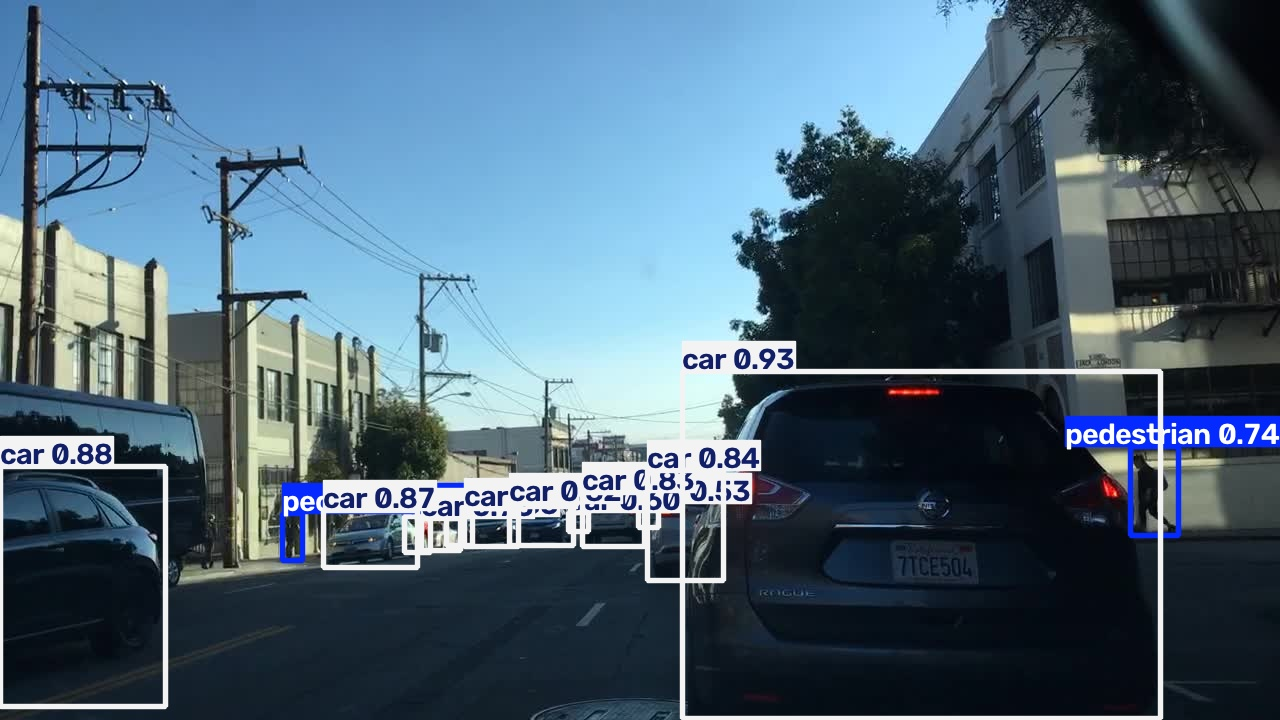

Results saved to /content/DriveSight/runs/visual_predictions
Image : 86c13f5c-cf72aced.jpg


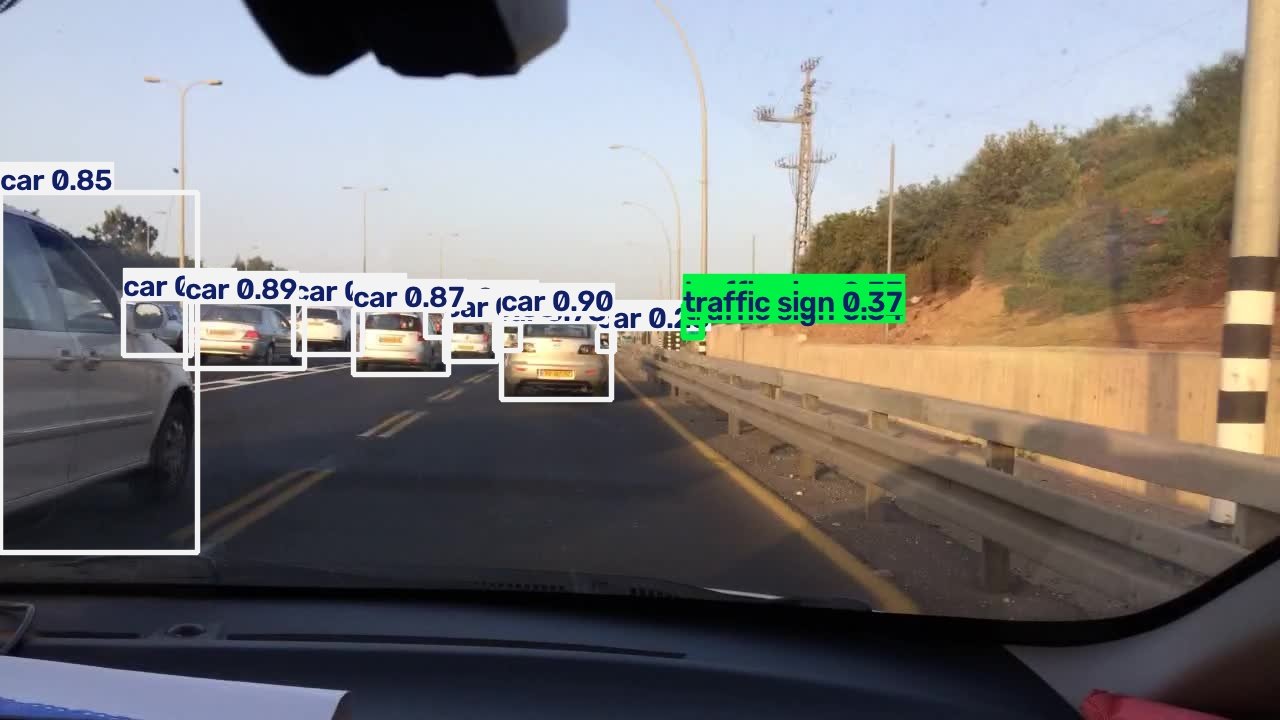

Results saved to /content/DriveSight/runs/visual_predictions
Image : 0b9fa855-936aae7a.jpg


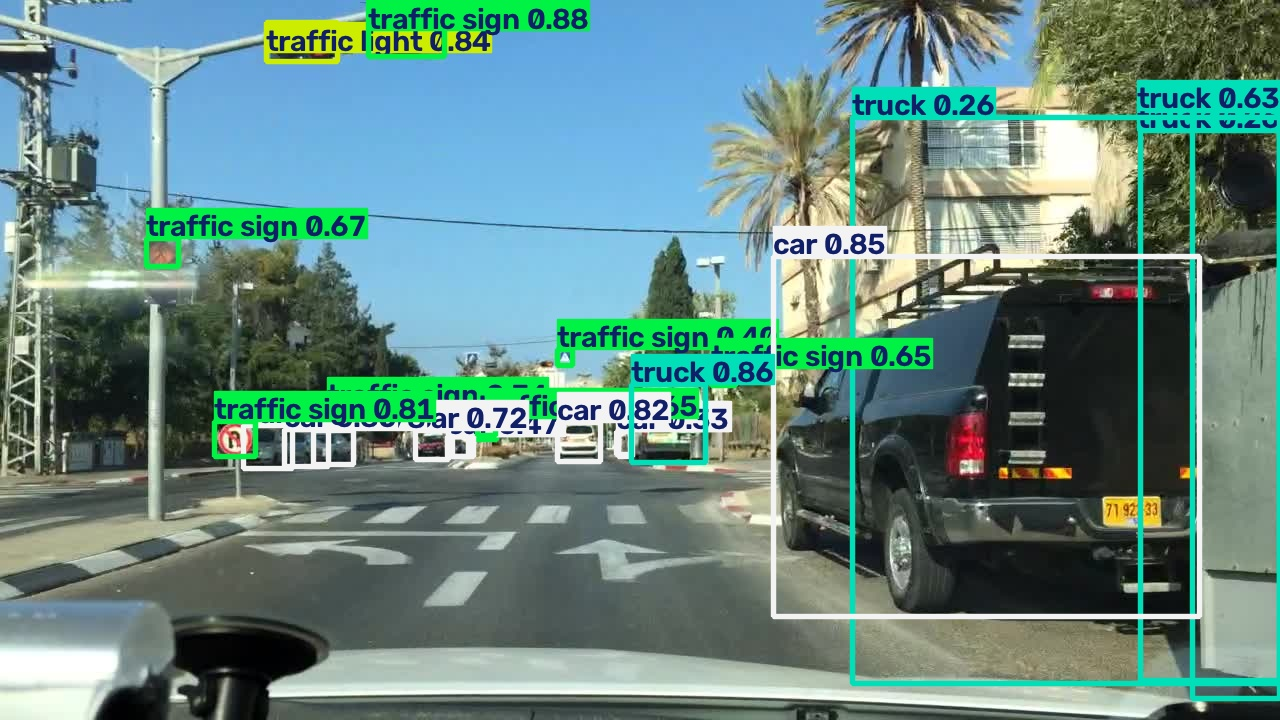

Results saved to /content/DriveSight/runs/visual_predictions
Image : 7aaf7c04-06077131.jpg


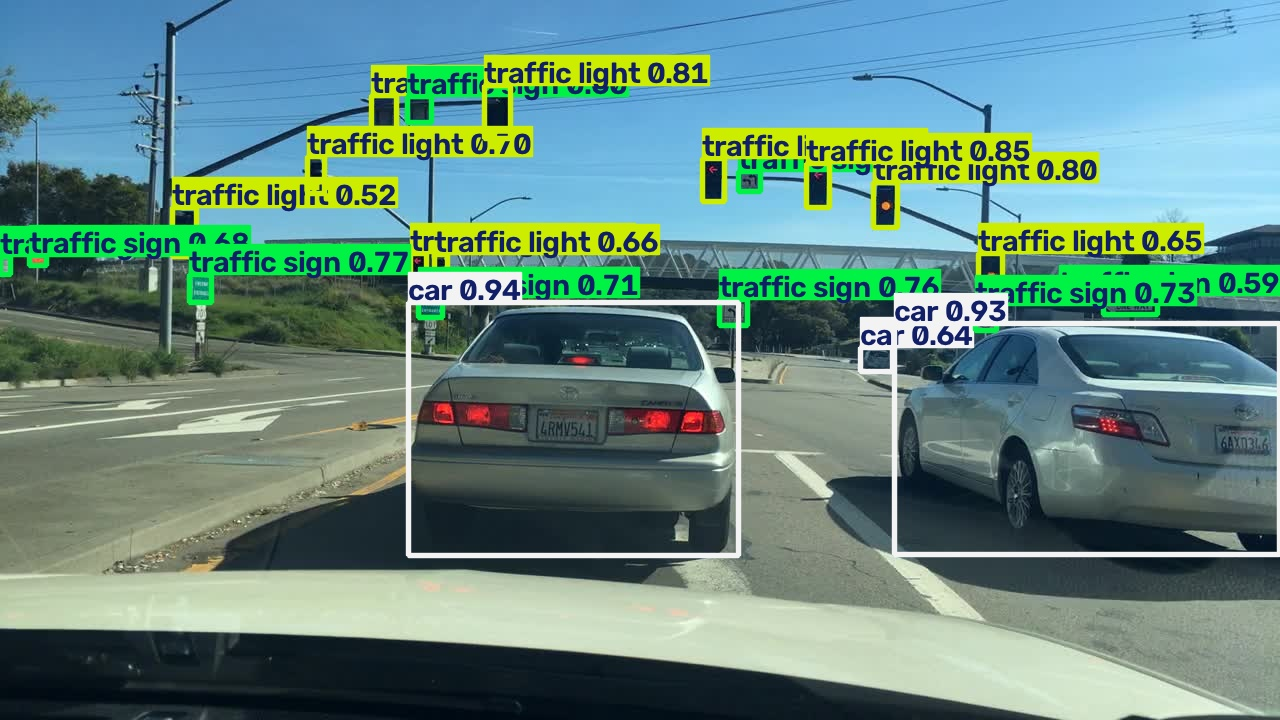

Results saved to /content/DriveSight/runs/visual_predictions
Image : 3b5918b2-aca4a8d6.jpg


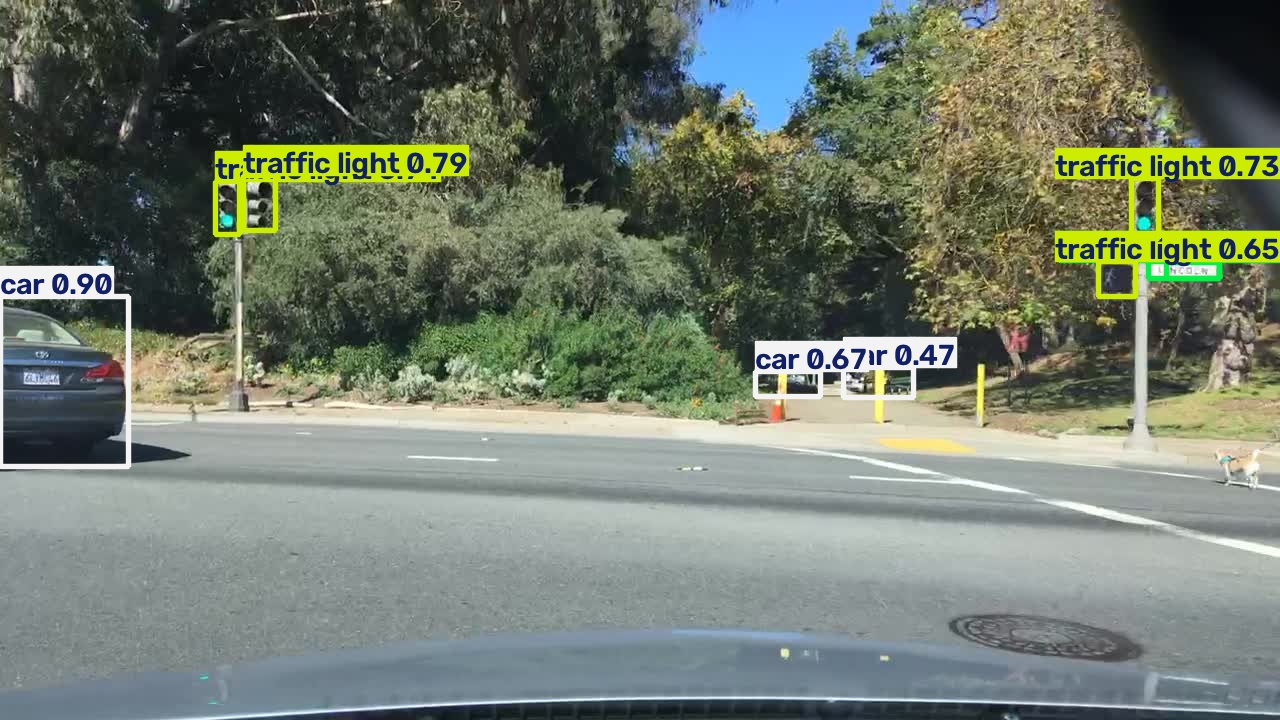

Results saved to /content/DriveSight/runs/visual_predictions
Image : 437a528e-65cd2b56.jpg


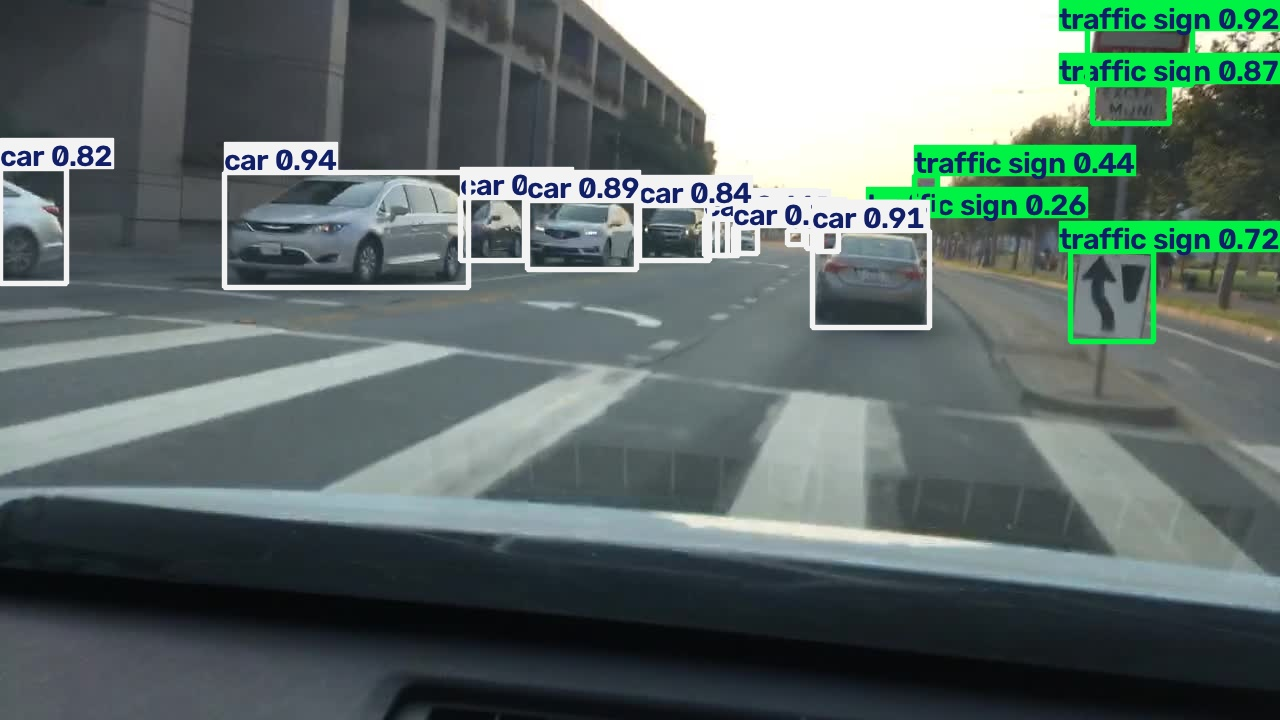

Results saved to /content/DriveSight/runs/visual_predictions
Image : 11886292-7b112025.jpg


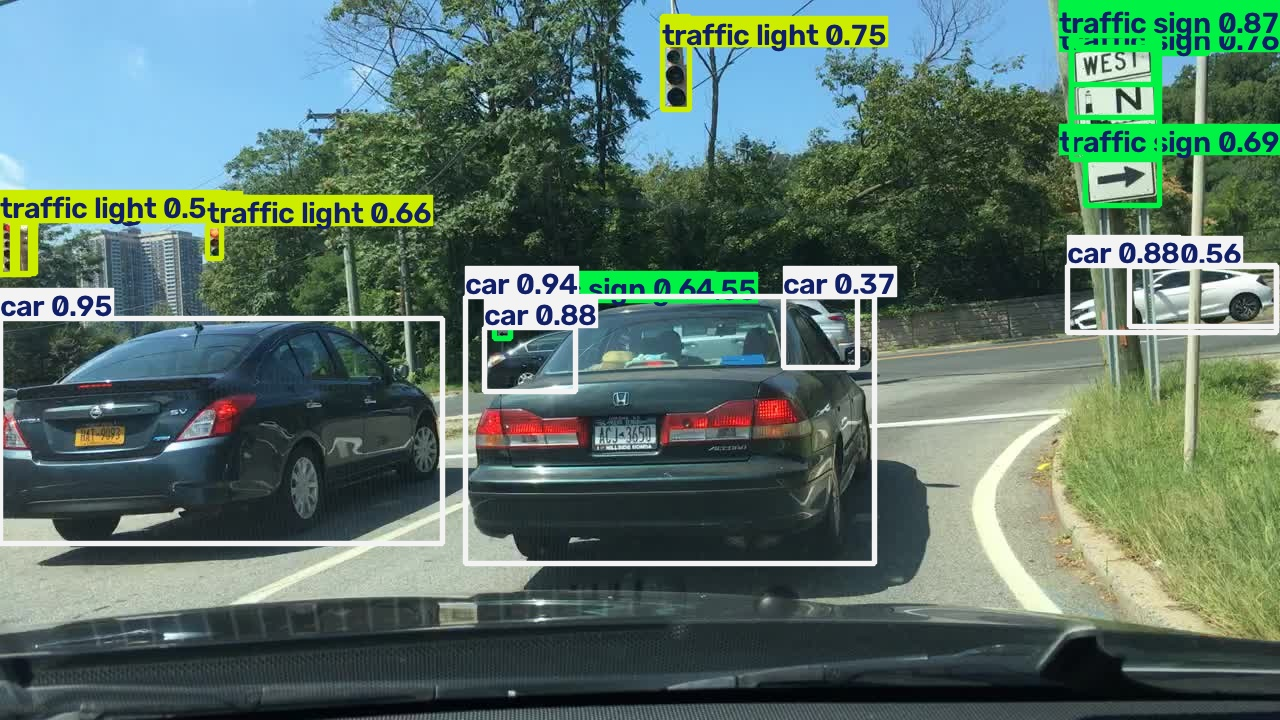

Results saved to /content/DriveSight/runs/visual_predictions
Image : 27248c22-a748e30f.jpg


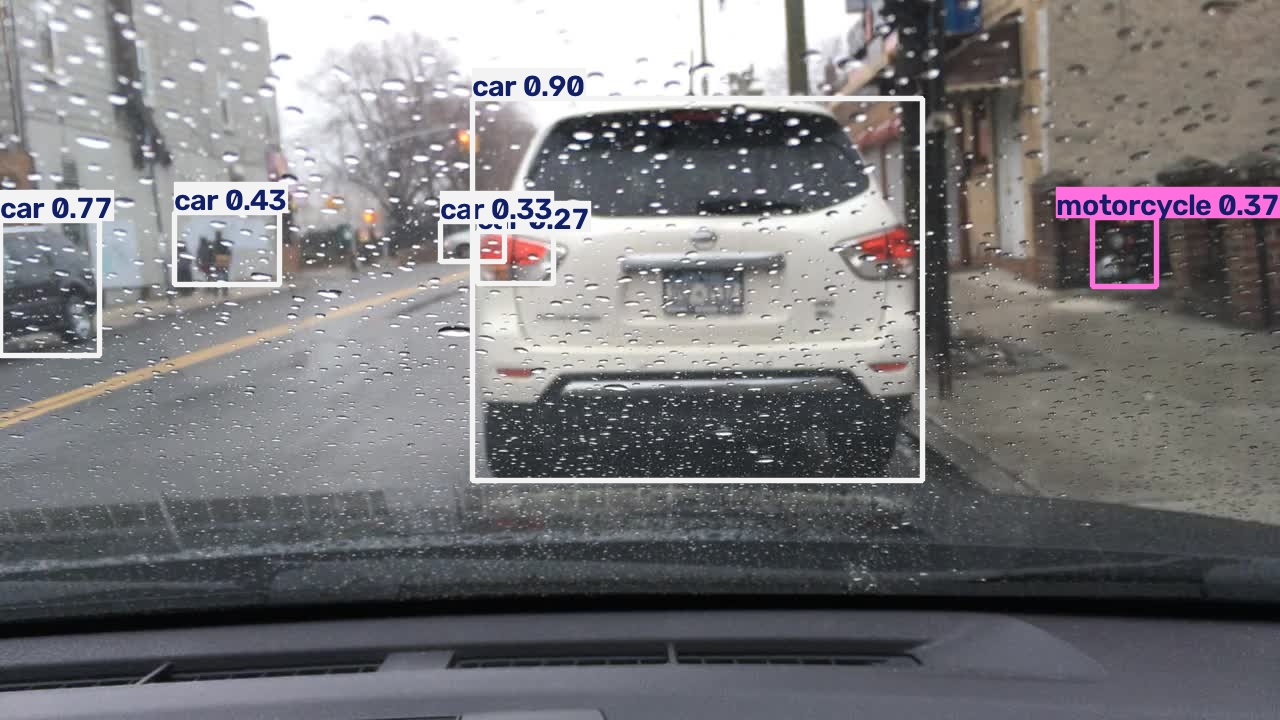

Results saved to /content/DriveSight/runs/visual_predictions
Image : 24937b75-917da3dd.jpg


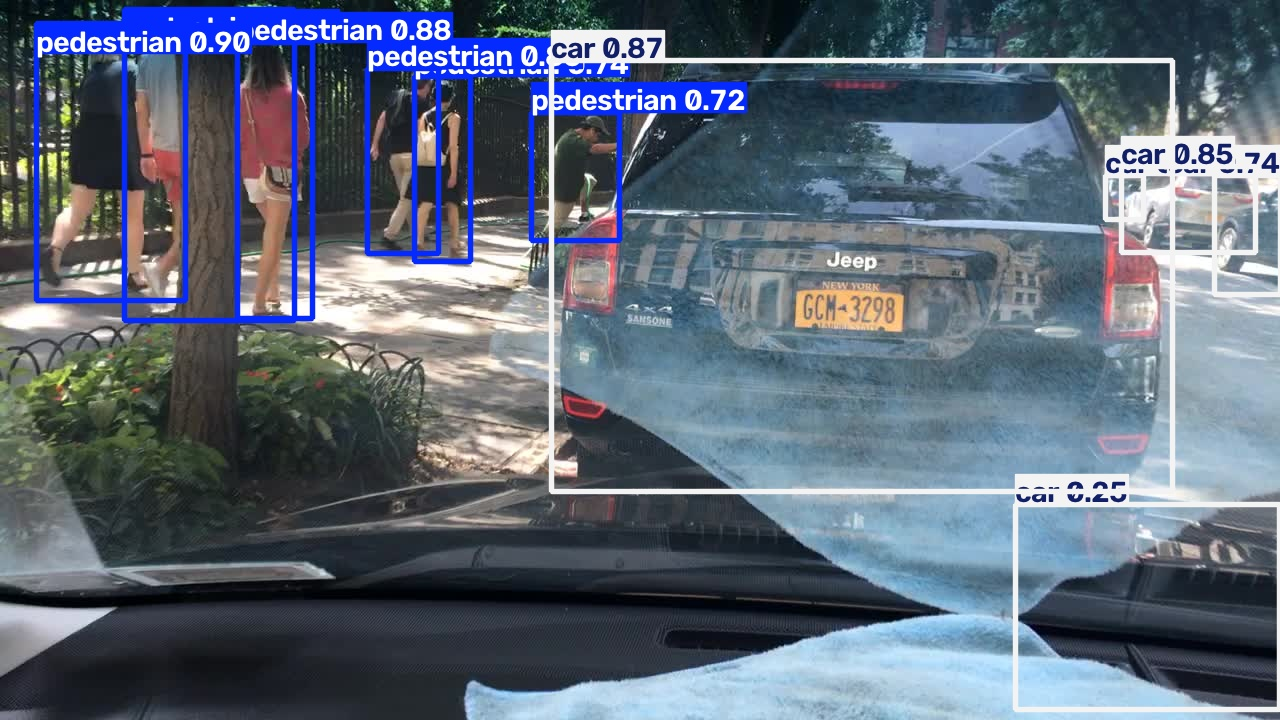

Results saved to /content/DriveSight/runs/visual_predictions
Image : 027e72be-02d4782f.jpg


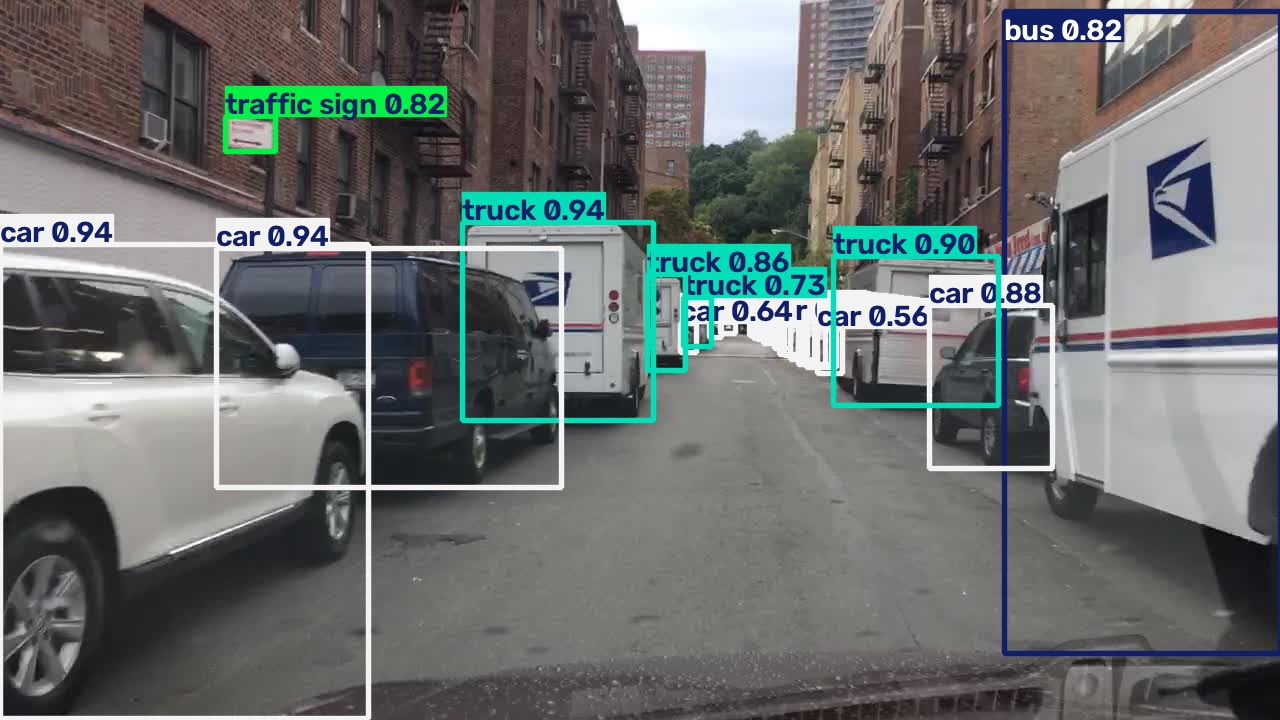

Results saved to /content/DriveSight/runs/visual_predictions
Image : 757190d5-06893864.jpg


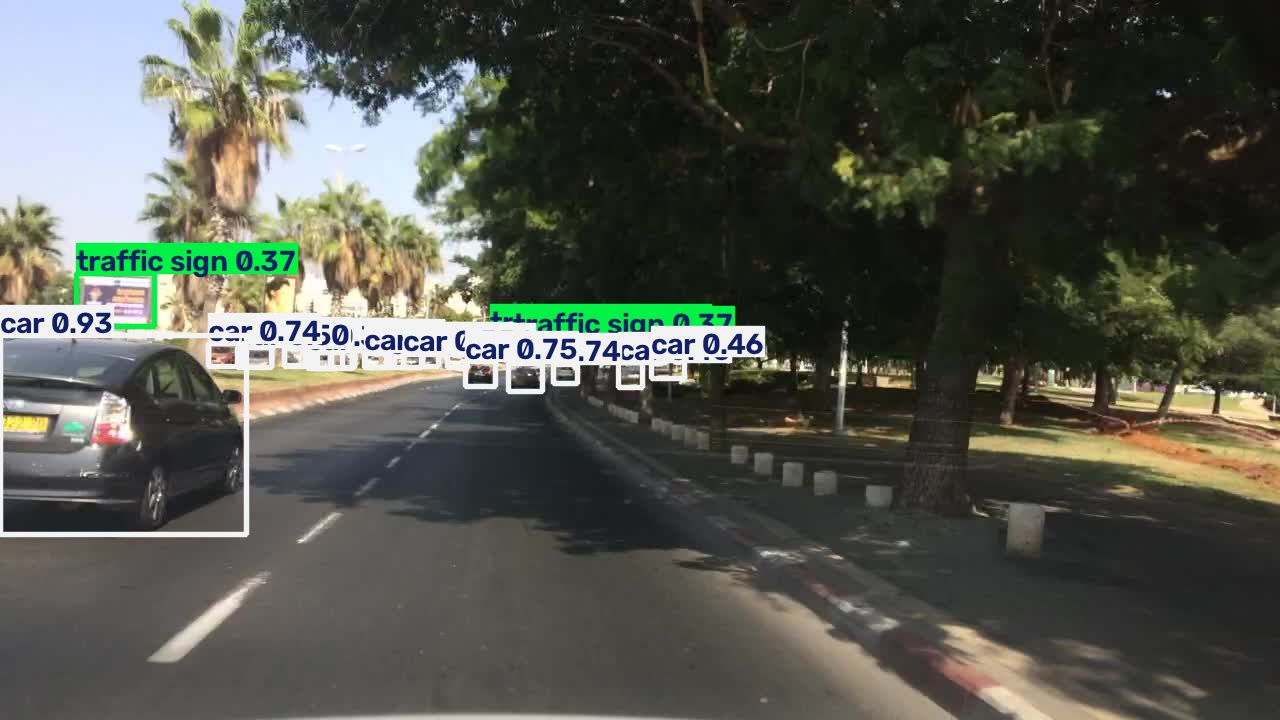

Results saved to /content/DriveSight/runs/visual_predictions
Image : 813ac0fa-296a3536.jpg


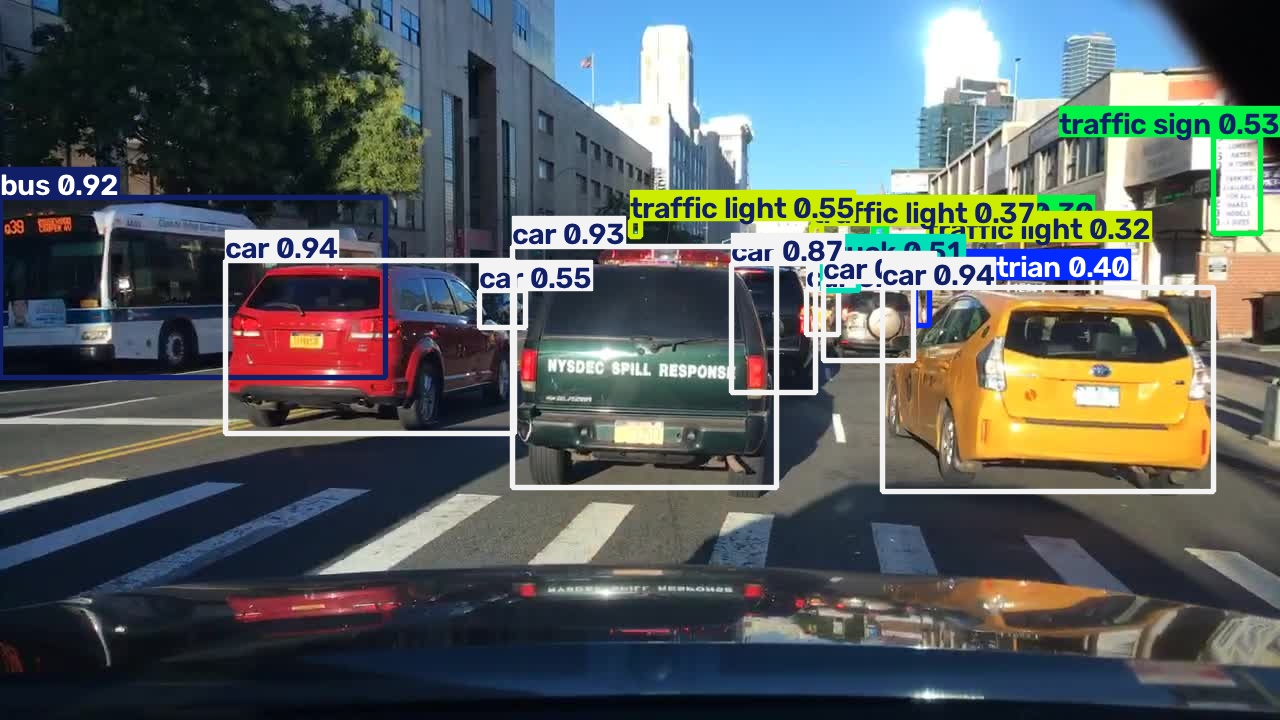

Results saved to /content/DriveSight/runs/visual_predictions
Image : 3bab7f42-98a3c175.jpg


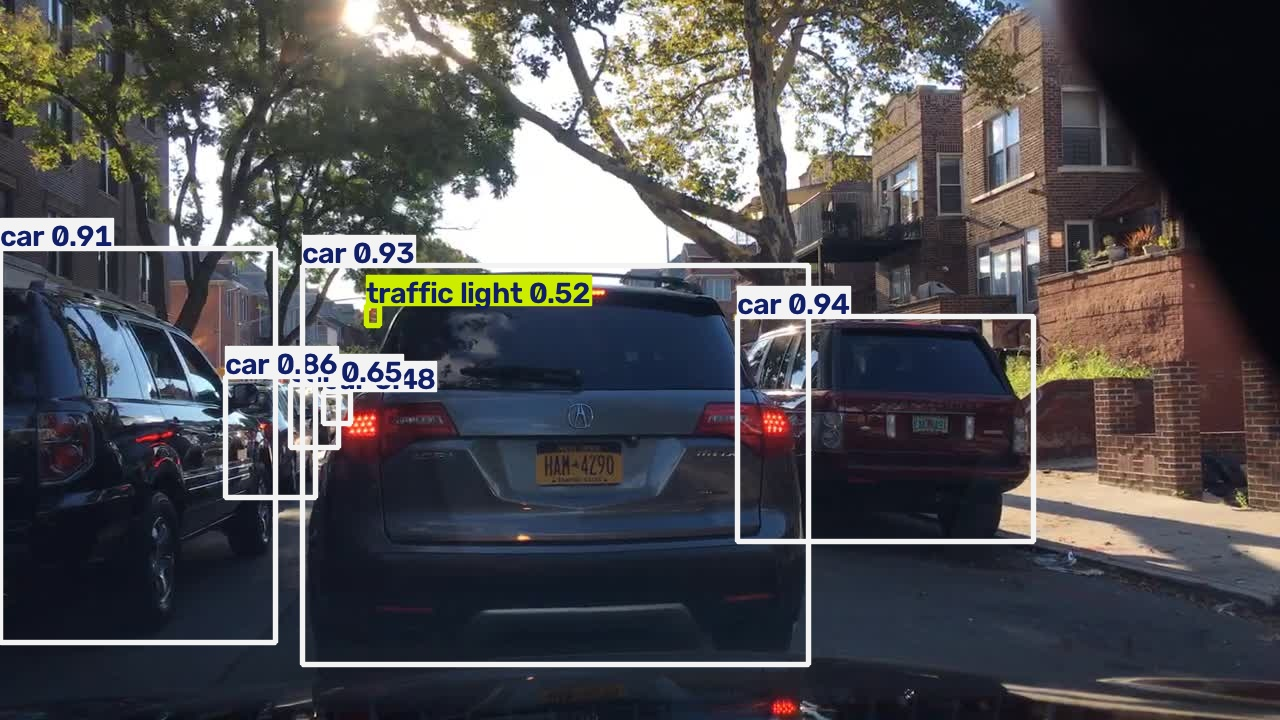

Results saved to /content/DriveSight/runs/visual_predictions
Image : 5a1f15c1-3e442248.jpg


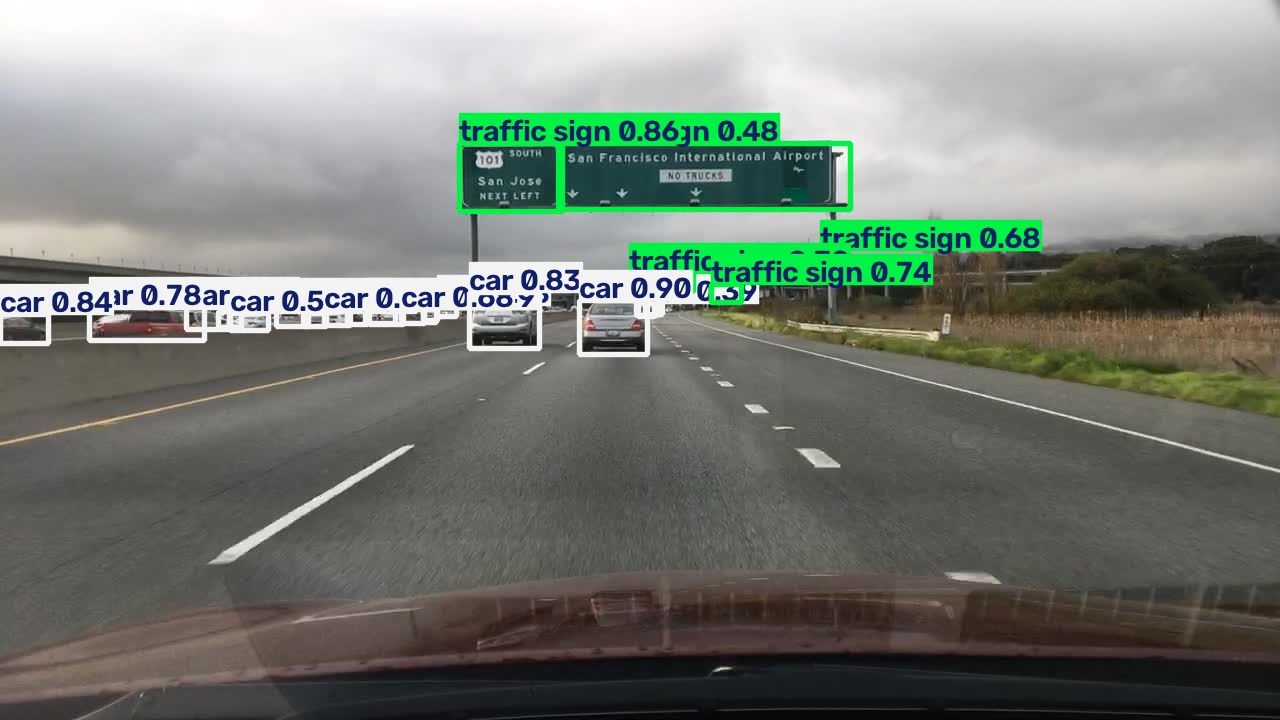

Results saved to /content/DriveSight/runs/visual_predictions
Image : 212b5e76-71679aa0.jpg


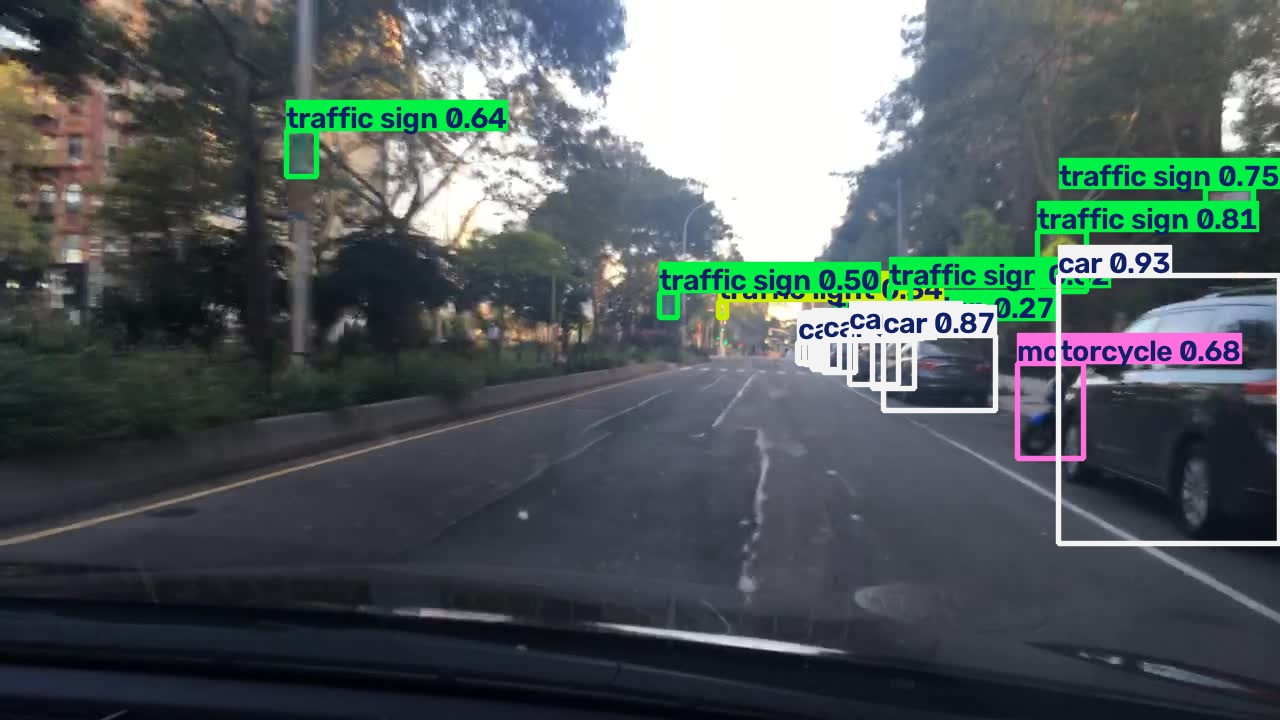

Results saved to /content/DriveSight/runs/visual_predictions
Image : 0f31361a-f207c44b.jpg


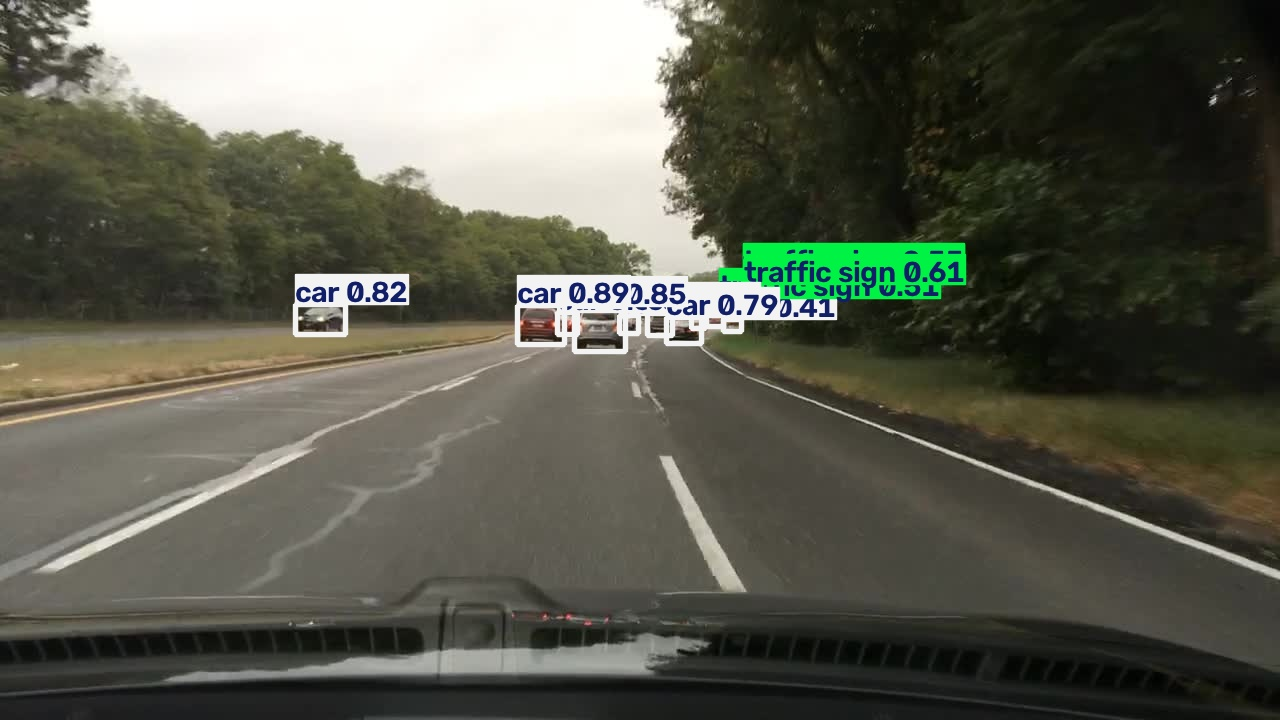

Results saved to /content/DriveSight/runs/visual_predictions
Image : 120b754f-77c28382.jpg


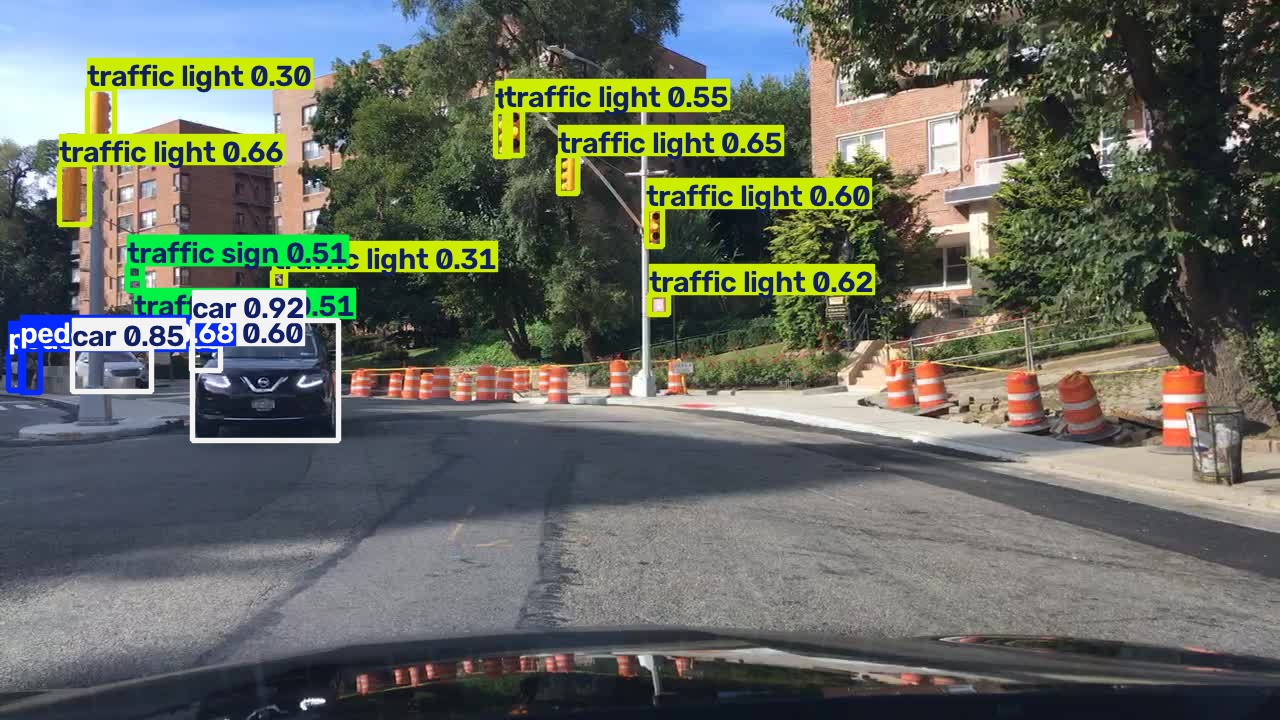

Results saved to /content/DriveSight/runs/visual_predictions
Image : 1597fb15-140c0eac.jpg


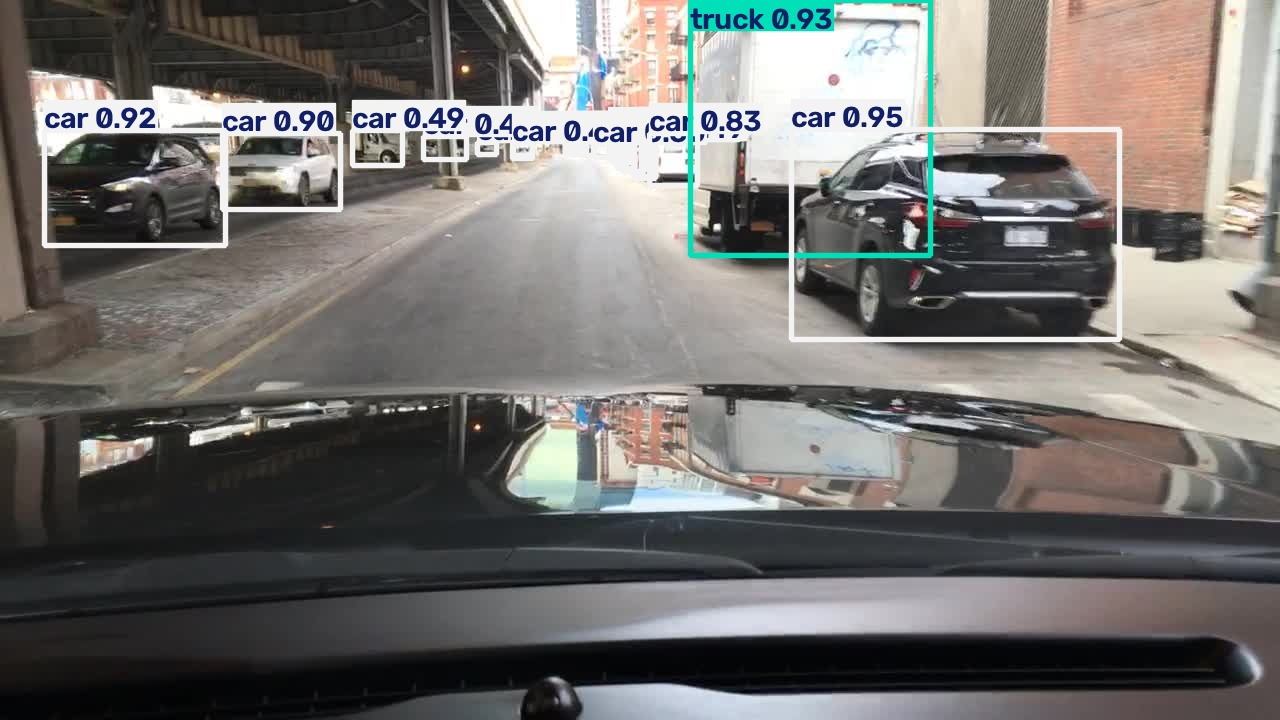

Results saved to /content/DriveSight/runs/visual_predictions
Image : 8b8ce47f-703b9530.jpg


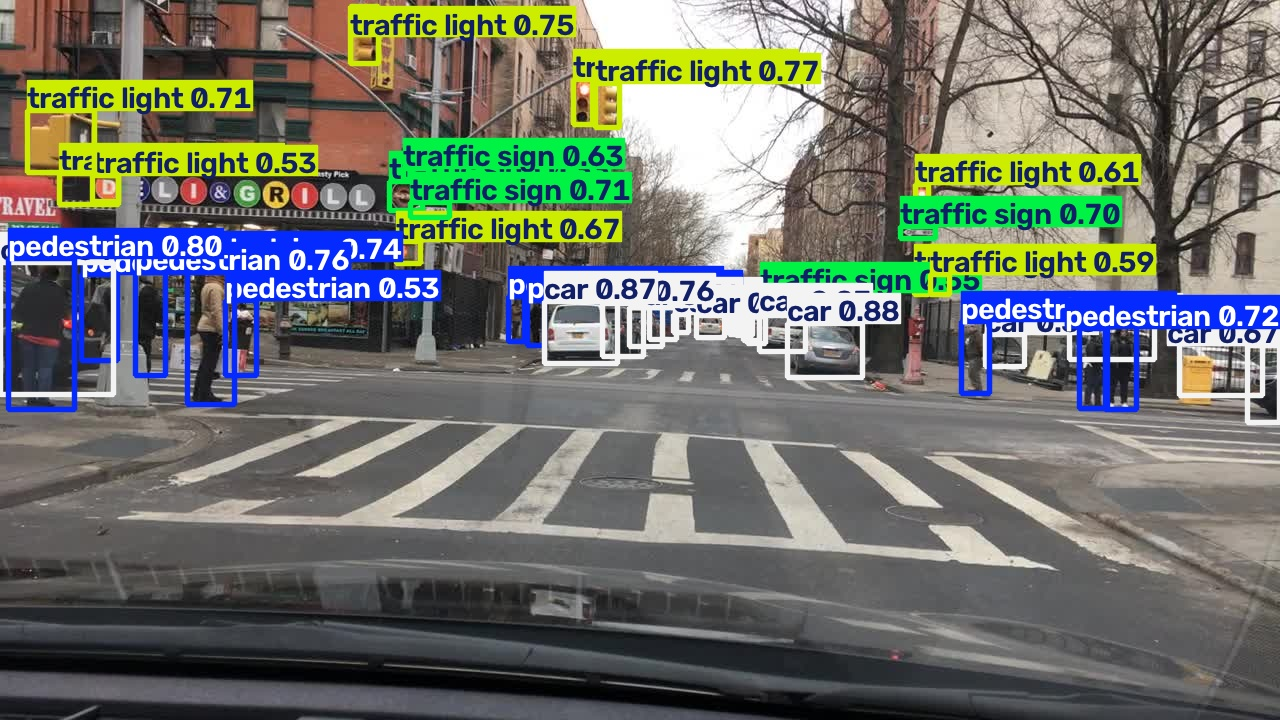

Results saved to /content/DriveSight/runs/visual_predictions
Image : 301e99f5-f1a9d13c.jpg


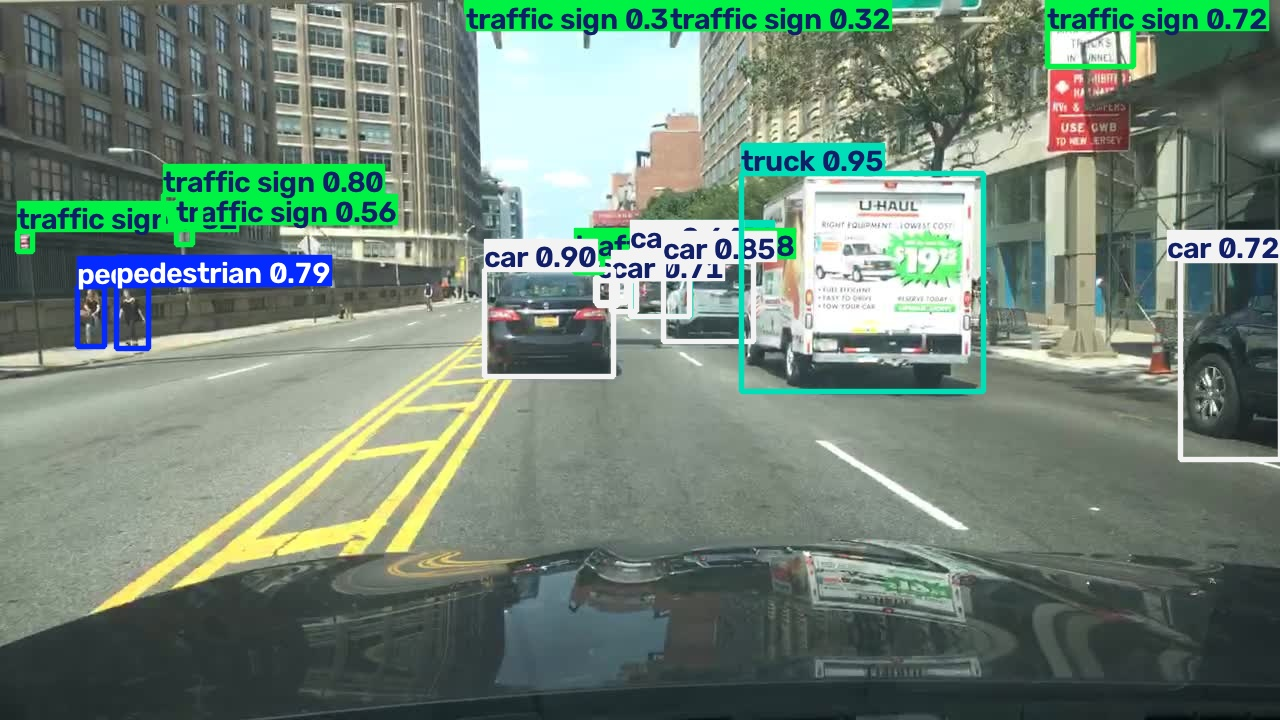

In [ ]:
from ultralytics import YOLO
import os
import glob
import random
from IPython.display import display, Image

# Charger le meilleur modèle entraîné
model = YOLO("/content/DriveSight/runs/bdd_yolov8s/weights/best.pt")

# Images du test set
test_images = glob.glob(
    "/content/DriveSight/data/yolo/images/test/*"
)

print("Nombre d'images disponibles :", len(test_images))

# Sélectionner 5 images aléatoires
random.seed(42)
selected_images = random.sample(test_images, min(20, len(test_images)))

# Générer et afficher les prédictions
for img_path in selected_images:
    results = model.predict(
        source=img_path,
        imgsz=960,
        conf=0.25,
        save=True,
        project="/content/DriveSight/runs",
        name="visual_predictions",
        exist_ok=True,
        verbose=False
    )

    print("Image :", os.path.basename(img_path))
    display(Image(filename=results[0].save_dir + "/" + os.path.basename(img_path)))

In [ ]:
%cd /content/DriveSight

from ultralytics import YOLO
from pathlib import Path
import random
import shutil

# Charger le modèle YOLOv8s entraîné
model_path = Path(
    "/content/DriveSight/runs/bdd_yolov8s/weights/best.pt"
)
model = YOLO(str(model_path))

# Récupérer les images du test set
test_dir = Path("/content/DriveSight/data/yolo/images/test")

images = sorted([
    p for p in test_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

assert len(images) >= 60, (
    f"Il faut au moins 60 images, mais seulement {len(images)} sont disponibles."
)

# Sélectionner 60 images de manière reproductible
random.seed(42)
selected_images = random.sample(images, 60)

# Dossier final des prédictions
output_dir = Path(
    "/content/DriveSight/experiments/yolo_model_comparison/visual_test_60"
)

# Nettoyer uniquement ce dossier de sortie
if output_dir.exists():
    shutil.rmtree(output_dir)

output_dir.mkdir(parents=True)

# Générer les prédictions et enregistrer les images annotées
for i, image_path in enumerate(selected_images, start=1):
    results = model.predict(
        source=str(image_path),
        imgsz=960,
        conf=0.25,
        device=0,
        verbose=False
    )

    # Dessiner les boîtes, classes et scores
    annotated = results[0].plot()

    # Enregistrer l'image annotée
    destination = output_dir / f"test_{i:03d}_{image_path.name}"

    import cv2
    success = cv2.imwrite(str(destination), annotated)

    if not success:
        raise RuntimeError(f"Échec de sauvegarde : {destination}")

print("Terminé !")
print("Dossier :", output_dir)
print("Nombre d'images :", len(list(output_dir.iterdir())))

/content/DriveSight
Terminé !
Dossier : /content/DriveSight/experiments/yolo_model_comparison/visual_test_60
Nombre d'images : 60


Nombre total d'images : 60
test_001_8289fae6-8b576293.jpg


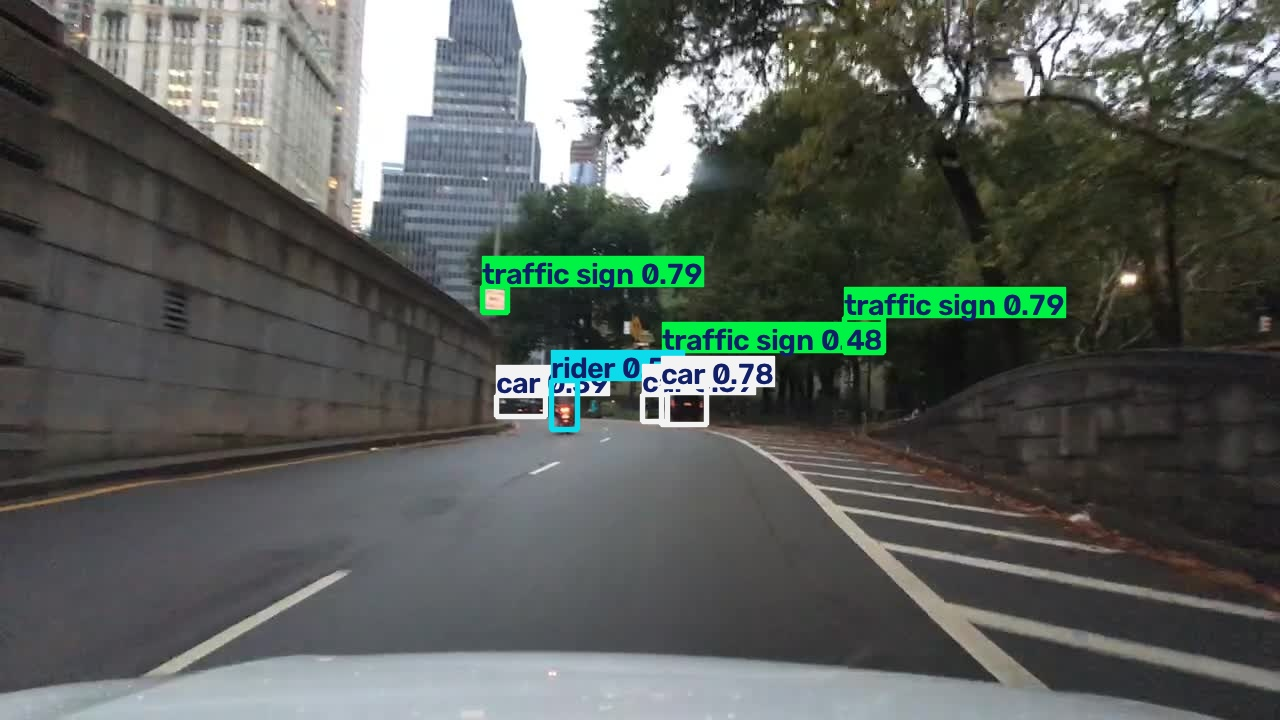

test_002_16dce9f0-8ef6f581.jpg


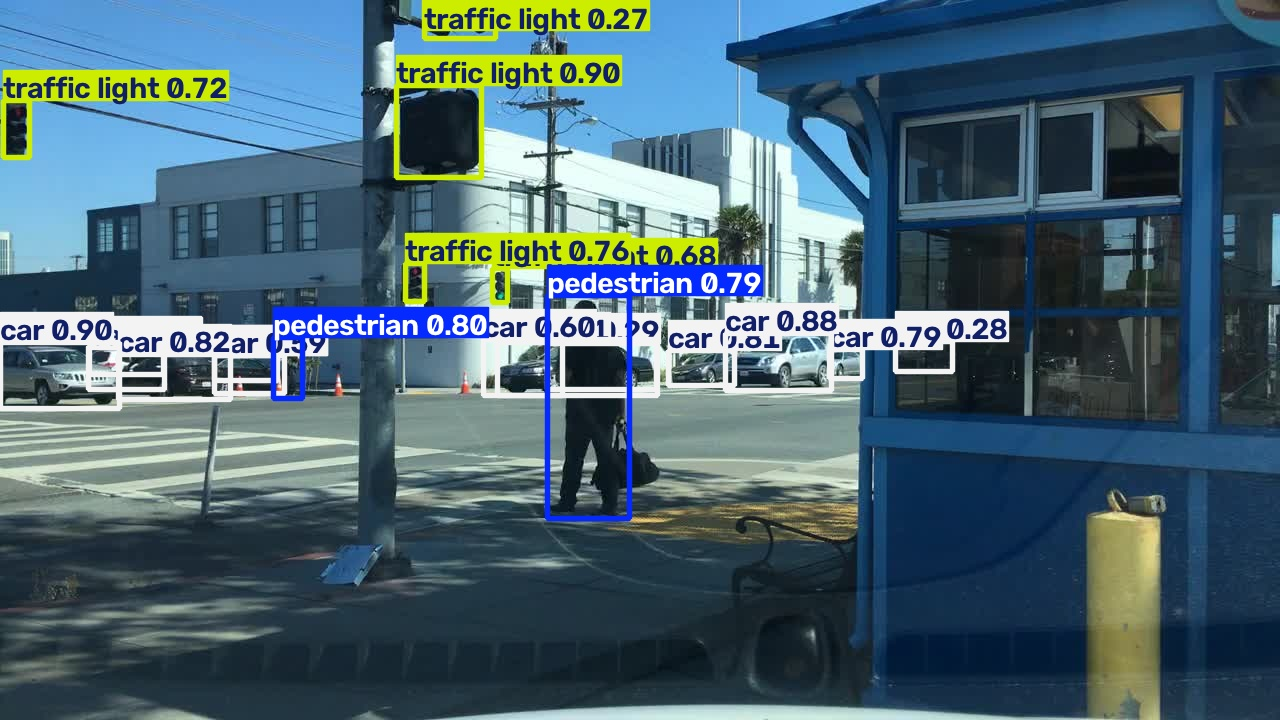

test_003_072a5b71-13456ded.jpg


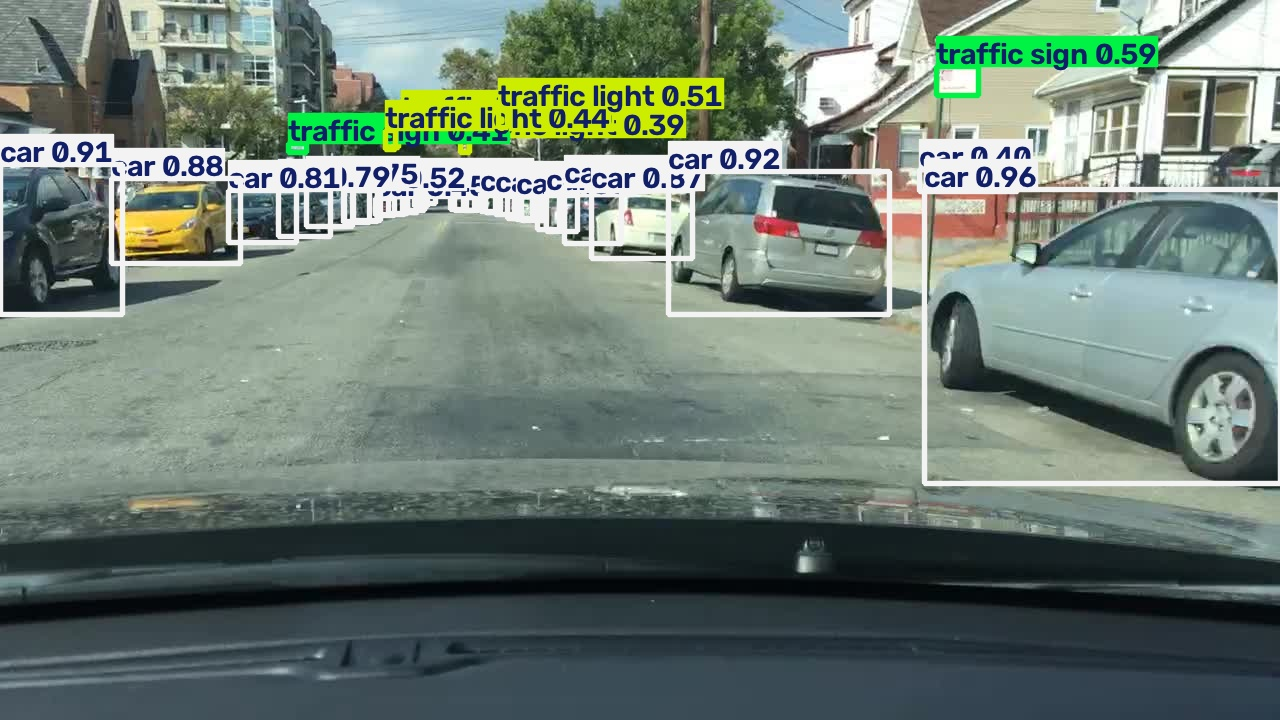

test_004_39964421-abb6de3b.jpg


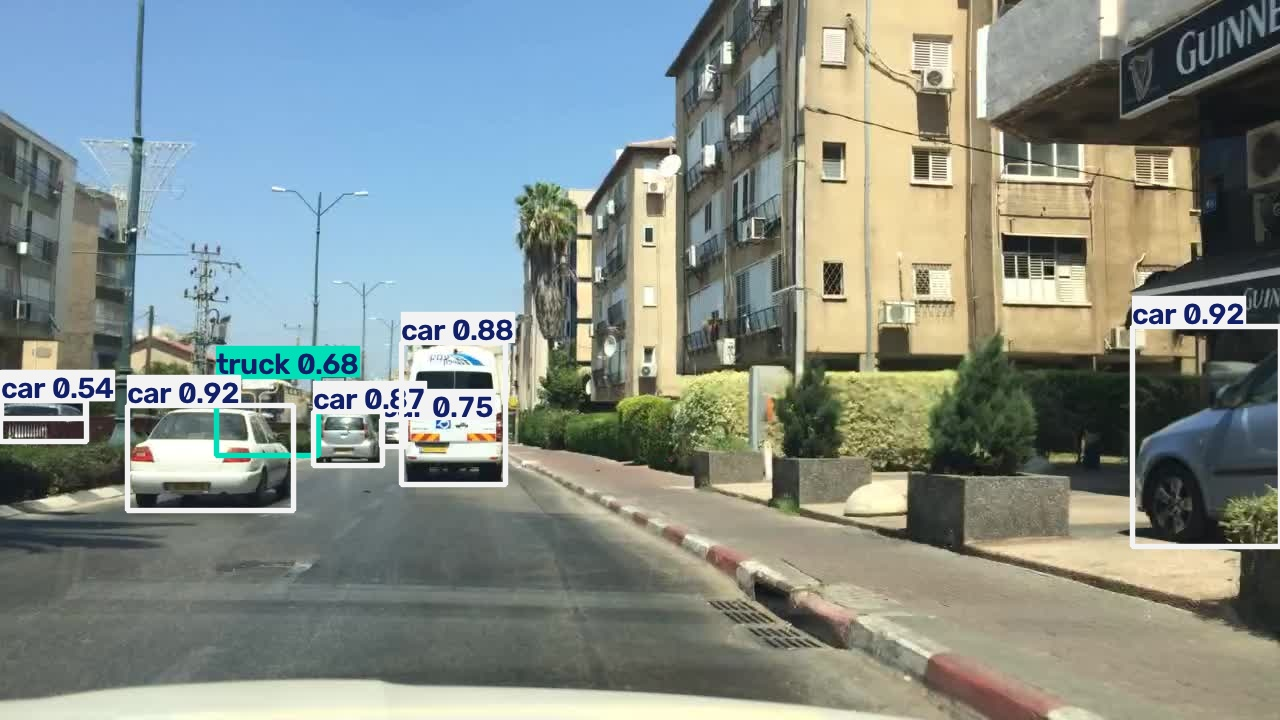

test_005_3360c76f-62914806.jpg


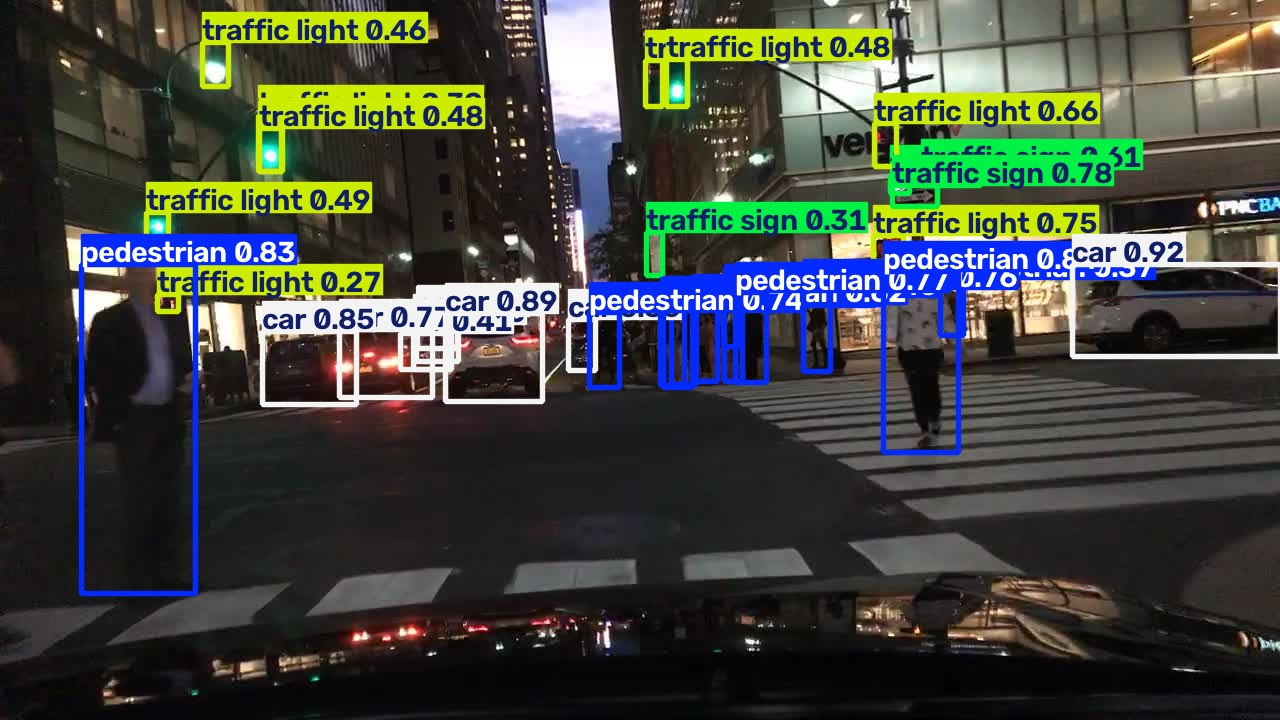

In [ ]:
from pathlib import Path
from IPython.display import display, Image

output_dir = Path(
    "/content/DriveSight/experiments/yolo_model_comparison/visual_test_60"
)

files = sorted(output_dir.glob("*"))

print(f"Nombre total d'images : {len(files)}")

for path in files[:5]:
    print(path.name)
    display(Image(filename=str(path)))